In [3]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

PyTorch version: 2.10.0+cpu
CUDA available: False


In [4]:
from pathlib import Path
import os

print("Working directory:", os.getcwd())
print("Training file exists:", Path("../data/train.json").exists())

Working directory: c:\Users\GugurGubil\Bita Drive\1. McMaster\1. Hamid Deep Learning\Project\notebooks
Training file exists: False


In [5]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

DATA_PATH = Path("../data/Annotations/train.json")

with open(DATA_PATH, "r", encoding="utf-8") as f:
    train_data = json.load(f)

print("Number of training examples:", len(train_data))
print("Dataset type:", type(train_data))
print("File exists:", DATA_PATH.exists())

Number of training examples: 20523
Dataset type: <class 'list'>
File exists: True


In [6]:
train_data[0]

{'image': 'VizWiz_train_00000000.jpg',
 'question': "What's the name of this product?",
 'answers': [{'answer_confidence': 'yes', 'answer': 'basil leaves'},
  {'answer_confidence': 'yes', 'answer': 'basil leaves'},
  {'answer_confidence': 'yes', 'answer': 'basil'},
  {'answer_confidence': 'yes', 'answer': 'basil'},
  {'answer_confidence': 'yes', 'answer': 'basil leaves'},
  {'answer_confidence': 'yes', 'answer': 'basil leaves'},
  {'answer_confidence': 'yes', 'answer': 'basil leaves'},
  {'answer_confidence': 'yes', 'answer': 'basil leaves'},
  {'answer_confidence': 'yes', 'answer': 'basil leaves'},
  {'answer_confidence': 'yes', 'answer': 'basil'}],
 'answer_type': 'other',
 'answerable': 1}

**Understanding the annotation**

Our first sample contains five important fields:

image, question, answers, answer_type, Answerability

VizWiz uses multiple human annotations because visual questions can have several valid answers.
an important challenge for our VQA model: different answers can be semantically equivalent without being identical strings.

Under the common VQA scoring rule, the predicted answer receives partial or full credit based on agreement with the reference answers. We will examine the exact evaluation rules for VizWiz before implementing our metric.

For our project, we may eventually evaluate both VQA answer accuracy and answerability prediction, depending on our project requirements.

## Dataset Statistics

We analyze the distribution of answerability labels and
answer types to understand class imbalance and its
implications for model training.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(train_data)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

print("\nAnswerability distribution:")
print(df["answerable"].value_counts())

print("\nAnswerability percentages:")
print(
    df["answerable"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nAnswer type distribution:")
print(df["answer_type"].value_counts())

Dataset shape: (20523, 5)

Columns: ['image', 'question', 'answers', 'answer_type', 'answerable']

Answerability distribution:
answerable
1    14991
0     5532
Name: count, dtype: int64

Answerability percentages:
answerable
1    73.04
0    26.96
Name: proportion, dtype: float64

Answer type distribution:
answer_type
other           13733
unanswerable     5532
yes/no            957
number            301
Name: count, dtype: int64


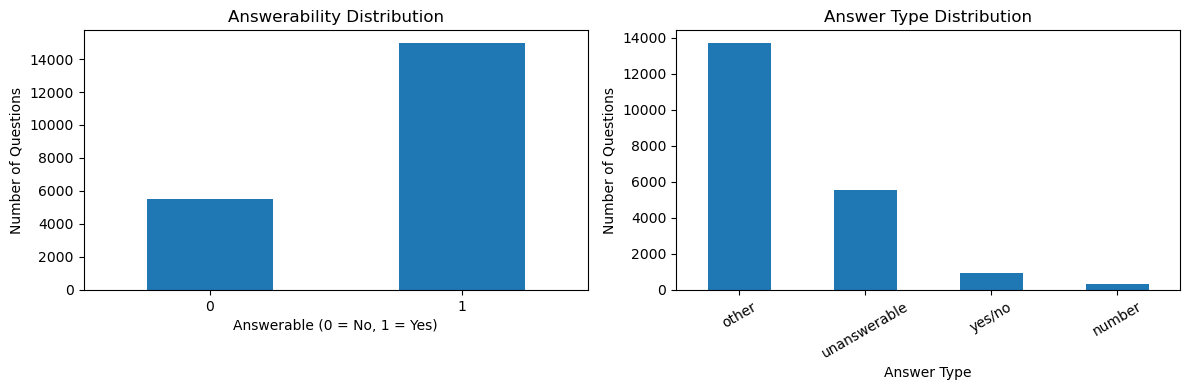

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["answerable"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0],
    title="Answerability Distribution"
)

axes[0].set_xlabel("Answerable (0 = No, 1 = Yes)")
axes[0].set_ylabel("Number of Questions")
axes[0].tick_params(axis="x", rotation=0)

df["answer_type"].value_counts().plot(
    kind="bar",
    ax=axes[1],
    title="Answer Type Distribution"
)

axes[1].set_xlabel("Answer Type")
axes[1].set_ylabel("Number of Questions")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [9]:
mismatch_count = (
    (df["answerable"] == 0)
    != (df["answer_type"] == "unanswerable")
).sum()

print("Mismatches:", mismatch_count)

Mismatches: 0


These labels are perfectly aligned in our training dataset.

We need to understand how much annotators agree before deciding how to create training targets.

## Count answer frequencies

In [10]:
from collections import Counter

def count_answers(answers):
    return Counter(
        a["answer"].strip().lower()
        for a in answers
    )

df["answer_counts"] = df["answers"].apply(count_answers)

df["top_answer"] = df["answer_counts"].apply(
    lambda counts: counts.most_common(1)[0][0]
)

df["top_answer_votes"] = df["answer_counts"].apply(
    lambda counts: counts.most_common(1)[0][1]
)

display(
    df[[
        "question",
        "top_answer",
        "top_answer_votes",
        "answerable"
    ]].head(10)
)

,question,top_answer,top_answer_votes,answerable
0,What's the name of this product?,basil leaves,7,1
1,Can you tell me what is in this can please?,coca cola,3,1
2,Is this enchilada sauce or is this tomatoes? ...,tomatoes,7,1
3,What is the captcha on this screenshot?,t36m,8,1
4,What is this item?,solar garden light,8,1
5,What's this?,shoes,4,1
6,What is in this bottle?,mouthwash,4,1
7,This item.,monitor cleaning kit,8,1
8,What color do these look?,orange,8,1
9,Surface look clean? Thank you.,yes,10,1


## Visualize annotator agreement

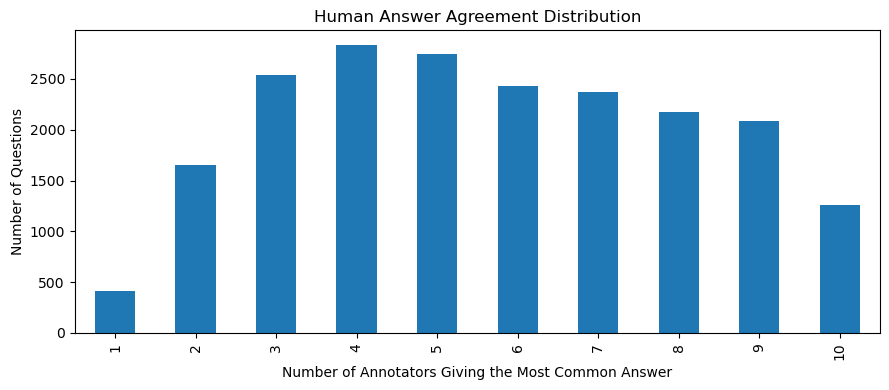

In [11]:
import matplotlib.pyplot as plt

agreement_counts = (
    df["top_answer_votes"]
    .value_counts()
    .sort_index()
)

ax = agreement_counts.plot(
    kind="bar",
    figsize=(9, 4),
    title="Human Answer Agreement Distribution"
)

ax.set_xlabel("Number of Annotators Giving the Most Common Answer")
ax.set_ylabel("Number of Questions")

plt.tight_layout()
plt.show()

## Inspect disagreement examples

In [12]:
low_agreement = df[
    (df["top_answer_votes"] <= 3) &
    (df["answerable"] == 1)
]

print("Low-agreement answerable examples:", len(low_agreement))

for _, row in low_agreement.head(5).iterrows():
    print("\nQuestion:", row["question"])
    print("Answers:", dict(row["answer_counts"]))
    print("Most common:", row["top_answer"])

Low-agreement answerable examples: 4606

Question: Can you tell me what is in this can please?
Answers: {'soda': 1, 'coca cola': 3, 'unanswerable': 2, 'coke 0': 2, 'coca cola 0': 1, 'coke': 1}
Most common: coca cola

Question: Is this.
Answers: {'android phone': 1, 'cell phone': 2, 'cellphone': 1, 'samsung phone': 1, 'unanswerable': 1, 'phone': 2, 'smart phone': 1, 'white smartphone': 1}
Most common: cell phone

Question: What is this? 
Answers: {'hot sauce': 1, 'conference room': 1, 'classroom': 1, 'meeting room': 1, 'office': 1, 'tv on stand': 1, 'liquid in bottle orange no label': 1, 'bottle': 2, 'image office tv desk': 1}
Most common: bottle

Question: What color furniture is that?  And is that nice table and chairs?
Answers: {'brown yes': 3, 'brown': 1, 'wood yes': 1, 'wood': 1, 'cherry': 1, 'nice dark red brown cherry furniture matches fan': 1, 'dark wood yes': 1, 'dark brown wood yes': 1}
Most common: brown yes

Question: This is a medication bottle and I'd just like to know if 

These results are very useful, we've discovered one of the central challenges of the VizWiz dataset: human annotators frequently disagree, even when they're describing the same object.
This has direct implications for how we prepare training labels and evaluate our BLIP model.

## Interpreting the agreement distribution
The graph shows that annotator agreement is spread across the entire range from 1 to 10 votes. There are 4,606 low-agreement answerable questions, which is a substantial portion of the answerable dataset.
However, we know that low exact-match agreement does not necessarily mean the image is ambiguous.

Based on some examples:

| Question | Human answers | Interpretation |
|---|---|---|
| What's in this can? | Coca Cola, Coke, Coke 0, soda | Similar answers with different specificity |
| Is this? | Cell phone, cellphone, smartphone, Samsung phone | Mostly equivalent or closely related terms |
| What is this? | Bottle, classroom, office, hot sauce | Genuine disagreement or ambiguity |
| What color furniture? | Brown, wood, cherry, dark brown | Different levels of detail |
| Is dosage information visible? | Yes, no, unanswerable | Genuine uncertainty about answerability |

Three important types of disagreement can be identified:

A. Semantic variation: Different words describe essentially the same thing, such as "cell phone" and "cellphone."

B. Different specificity: One annotator says "soda," another says "Coca Cola," and another identifies a particular variety.

C. Genuine disagreement: Annotators describe entirely different objects or disagree about whether an image contains enough information.

These shouldn't all be treated identically when interpreting model errors.

**An important issue with majority-answer labels**
Considering examples like this:

Question: Is dosage information visible?

yes: 2
no: 2
unanswerable: 3
not visible: 1
has label not sure about dosage: 1
but image is blurry: 1

The most frequent answer is "unanswerable", with only three votes.

But that doesn't necessarily make it a reliable ground-truth answer.

Your current method picks a single answer regardless of the strength of agreement.

For BLIP fine-tuning, we could initially use majority-vote labels as a simple baseline. However, we should preserve all ten original answers for evaluation and consider better target-selection strategies during experimentation.

Also, the answerable label is not necessarily determined by whether every human annotator gives an answer. Your examples show that some questions labeled answerable still have individual "unanswerable" responses.


## Analyzing answer vocabulary and coverage
How many different answers exist in VizWiz, and how much of the dataset can a fixed-answer classification model cover?



**Count the most common answers**

In [13]:
from collections import Counter

all_answers = [
    a["answer"].strip().lower()
    for answers in df["answers"]
    for a in answers
]

answer_freq = Counter(all_answers)

print("Total human answers:", len(all_answers))
print("Unique answers:", len(answer_freq))

print("\nTop 20 most common answers:")
for answer, count in answer_freq.most_common(20):
    print(f"{answer:30s} {count}")

Total human answers: 205230
Unique answers: 41226

Top 20 most common answers:
unanswerable                   55993
no                             5271
yes                            4559
white                          2490
grey                           2216
black                          2076
blue                           1810
red                            1191
brown                          814
pink                           805
green                          780
keyboard                       674
purple                         581
soup                           524
nothing                        508
dog                            504
yellow                         466
phone                          458
tan                            404
laptop                         404


**Analyze answer vocabulary coverage**

What percentage of questions have a majority-vote answer included in the top-K most frequent answers.
(Why we are investigating this? A classification model restricted to the top 1,000 answers wouldn't be able to predict answers outside that vocabulary.But a generative model such as BLIP can produce answers that aren't explicitly listed as classification labels. This is one of the trade-offs we'll investigate when choosing our baseline.)

In [14]:
import pandas as pd

vocab_sizes = [10, 50, 100, 500, 1000, 2000, 5000]

coverage_results = []

for k in vocab_sizes:
    vocab = {
        answer for answer, _ in answer_freq.most_common(k)
    }

    coverage = df["top_answer"].isin(vocab).mean() * 100

    coverage_results.append({
        "Vocabulary Size": k,
        "Coverage (%)": round(coverage, 2)
    })

coverage_df = pd.DataFrame(coverage_results)

display(coverage_df)

,Vocabulary Size,Coverage (%)
0,10,48.47
1,50,55.61
2,100,59.53
3,500,70.02
4,1000,75.46
5,2000,81.46
6,5000,92.02


**Visualize coverage**

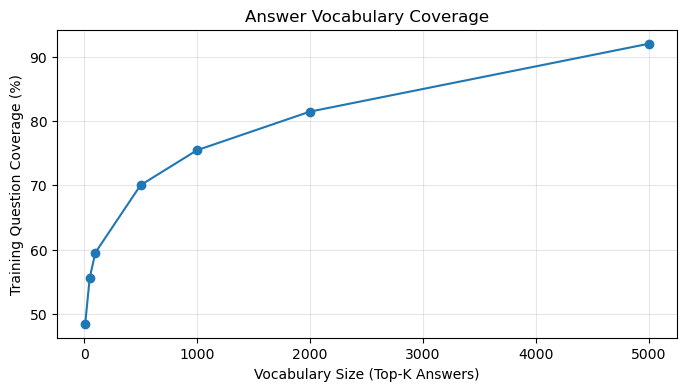

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    coverage_df["Vocabulary Size"],
    coverage_df["Coverage (%)"],
    marker="o"
)

plt.xlabel("Vocabulary Size (Top-K Answers)")
plt.ylabel("Training Question Coverage (%)")
plt.title("Answer Vocabulary Coverage")
plt.grid(alpha=0.3)

plt.show()

**Findings:**

Finding 1: The answer vocabulary is extremely diverse
You have 41,226 unique answer strings across 205,230 human annotations.

This means there are many different ways to answer questions, including synonyms, detailed descriptions, spelling variations, and rare objects.

A fixed-vocabulary classifier may struggle with uncommon answers. A generative model like BLIP has the advantage of producing text beyond a predefined answer list.
Finding 2: The most frequent answer is overwhelmingly "unanswerable"

The "unanswerable" response alone accounts for approximately 27.3% of all human annotations.

This helps explain your vocabulary-coverage results.
Finding 3: Your top-10 vocabulary covers 48.47% of training questions
This is surprisingly high at first glance.

But remember: "unanswerable" is one of those ten answers, and approximately 27% of questions are labeled unanswerable.

Other frequent answers, including colours and yes/no responses, also account for many questions.

Therefore, we should not interpret 48.47% coverage as evidence that a classifier with ten labels would perform well.

Coverage only tells us whether a reference answer belongs to the vocabulary. It doesn't mean the classifier can predict the correct answer.

Finding 2: The most frequent answer is overwhelmingly "unanswerable"
The "unanswerable" response alone accounts for approximately 27.3% of all human annotations.
This helps explain the vocabulary-coverage results.

Finding 3: Your top-10 vocabulary covers 48.47% of training questions
This is surprisingly high at first glance.

But remember: "unanswerable" is one of those ten answers, and approximately 27% of questions are labeled unanswerable.

Other frequent answers, including colours and yes/no responses, also account for many questions.

Therefore, we should not interpret 48.47% coverage as evidence that a classifier with ten labels would perform well.

Coverage only tells us whether a reference answer belongs to the vocabulary. It doesn't mean the classifier can predict the correct answer.

Now we need to see what happens if we exclude unanswerable questions.

**Answerable-only coverage**

In [16]:
answerable_df = df[df["answerable"] == 1].copy()

# Build vocabulary only from answers to answerable questions
answerable_answers = [
    a["answer"].strip().lower()
    for answers in answerable_df["answers"]
    for a in answers
    if a["answer"].strip().lower() != "unanswerable"
]

answerable_freq = Counter(answerable_answers)

vocab_sizes = [10, 50, 100, 500, 1000, 2000, 5000]

results = []

for k in vocab_sizes:
    vocab = {
        answer
        for answer, _ in answerable_freq.most_common(k)
    }

    coverage = answerable_df["top_answer"].isin(vocab).mean() * 100

    results.append({
        "Vocabulary Size": k,
        "Answerable Coverage (%)": round(coverage, 2)
    })

answerable_coverage_df = pd.DataFrame(results)

display(answerable_coverage_df)

,Vocabulary Size,Answerable Coverage (%)
0,10,16.32
1,50,25.88
2,100,31.24
3,500,45.76
4,1000,53.21
5,2000,61.36
6,5000,76.11


We exclude "unanswerable" from the vocabulary, even though some answerable examples contain individual "unanswerable" annotations.

This gives us a clearer picture of how much vocabulary is required for answerable visual questions.

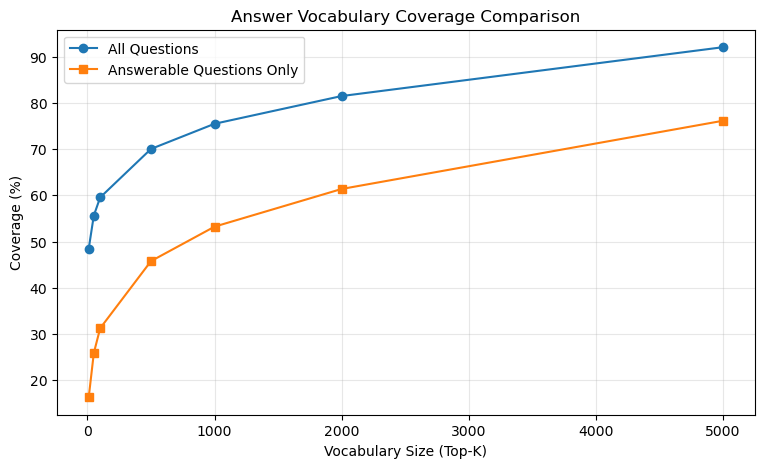

In [17]:
plt.figure(figsize=(9, 5))

plt.plot(
    coverage_df["Vocabulary Size"],
    coverage_df["Coverage (%)"],
    marker="o",
    label="All Questions"
)

plt.plot(
    answerable_coverage_df["Vocabulary Size"],
    answerable_coverage_df["Answerable Coverage (%)"],
    marker="s",
    label="Answerable Questions Only"
)

plt.xlabel("Vocabulary Size (Top-K)")
plt.ylabel("Coverage (%)")
plt.title("Answer Vocabulary Coverage Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

The answer vocabulary is much more diverse when we exclude unanswerable questions.
Finding 1: A small answer vocabulary is insufficient
With the top 1,000 answers, we cover:
- 75.46% of all training questions.
- Only 53.21% of answerable training questions.
This means almost half of the answerable questions have a most-common answer outside the top 1,000 vocabulary.

Even increasing the vocabulary to 5,000 answers leaves approximately 24% of answerable questions outside our selected vocabulary.

This supports using a generative approach such as BLIP for the main model.
Finding 2: The unanswerable class inflates overall coverage
The difference between the two curves is substantial, especially at small vocabulary sizes.

This happens largely because "unanswerable" is extremely frequent.

Consequently, measuring only overall accuracy could hide important weaknesses in answering actual visual questions.

Finding 3: A 1,000-answer classifier is still useful as a baseline
Although a 1,000-answer vocabulary cannot cover every question, it can still serve as a meaningful baseline.

For example:
- A question-only classifier can reveal how much performance is possible from language patterns alone.
- BLIP can then demonstrate the benefit of using visual information.
- BLIP fine-tuning can show the improvement from adapting a pretrained model to VizWiz.
One qualification: our current coverage metric checks whether the most common reference answer is in the vocabulary. It is not a strict upper bound on official VQA accuracy, because other human answers can also receive partial or full credit.

**Display sample images with their questions**

In [18]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

IMAGE_DIR = Path("../data/train")

def show_examples(dataframe, n=6, seed=42):
    samples = dataframe.sample(
        n=min(n, len(dataframe)),
        random_state=seed
    )

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()

    for ax, (_, row) in zip(axes, samples.iterrows()):
        image_path = IMAGE_DIR / row["image"]

        with Image.open(image_path) as image:
            ax.imshow(image.convert("RGB"))

        ax.axis("off")

        ax.set_title(
            f"Q: {row['question'][:65]}\n"
            f"Answer: {row['top_answer']}\n"
            f"Answerable: {row['answerable']}",
            fontsize=10
        )

    for ax in axes[len(samples):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

**Visualize answerable examples**

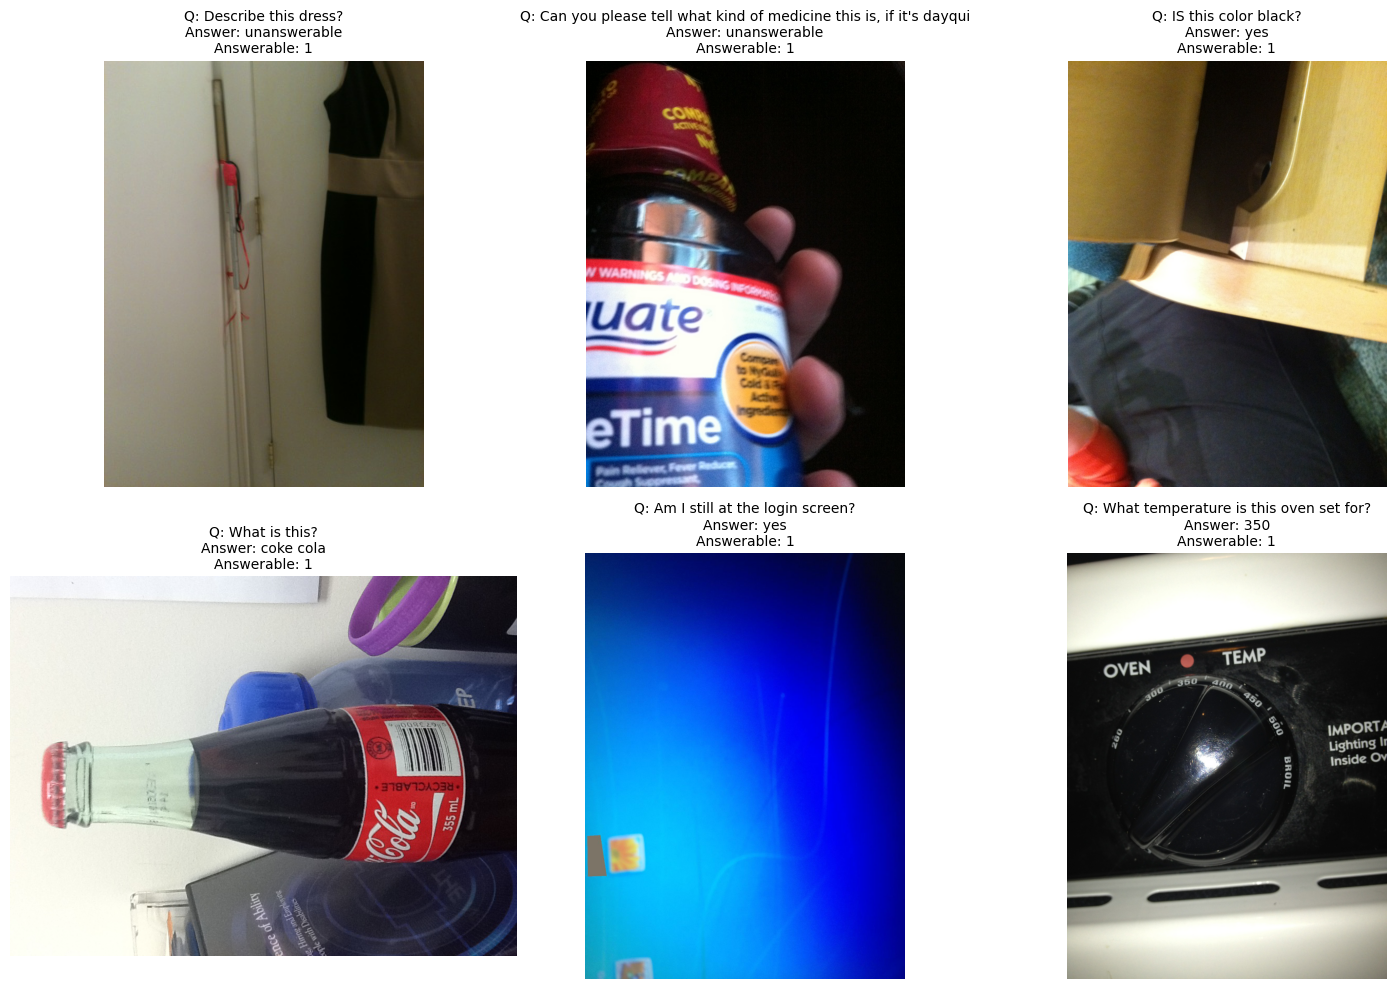

In [19]:
show_examples(
    df[df["answerable"] == 1],
    n=6
)

**Visualize unanswerable examples**

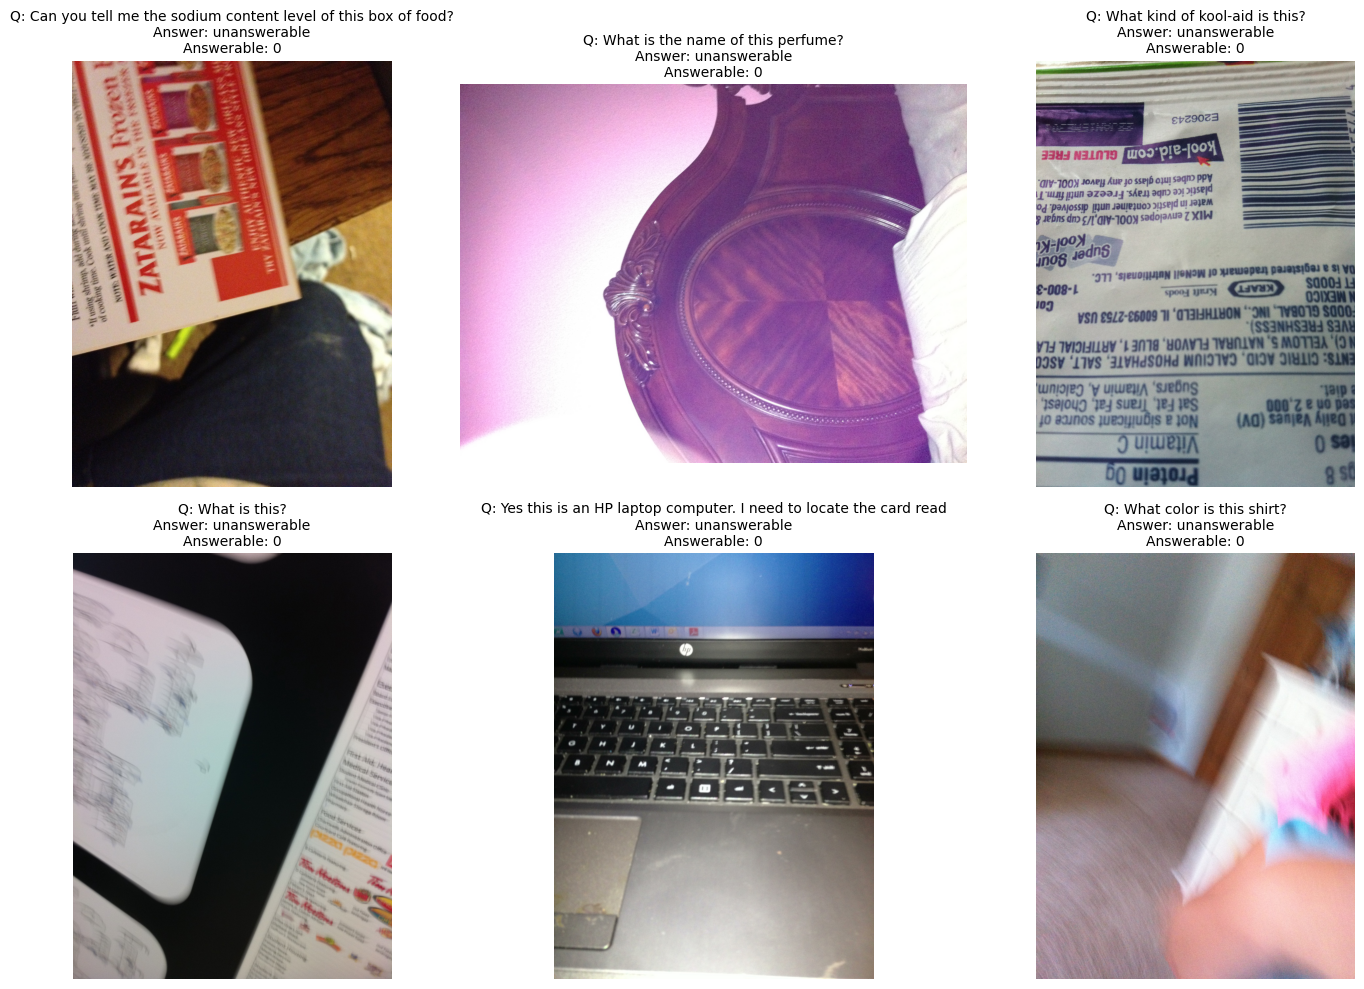

In [20]:
show_examples(
    df[df["answerable"] == 0],
    n=6
)

**1. Interpretation from the images**
| Challenge | Example from your images | Implication for VQA |
|---|---|---|
| Poor framing | Asking about a dress when most of it is outside the frame | The model needs to recognize missing visual information |
| Small or unclear text | Sodium content on a food box | Reading text may require OCR capabilities |
| Image rotation | Coca-Cola bottle and Kool-Aid package | Models need robustness to orientation |
| Blur | Shirt colour question | The model must avoid unreliable guesses |
| Question–image mismatch | Asking about perfume when the image shows furniture | The model needs to recognize when the requested object is absent |
| Fine-grained visual reasoning | Oven temperature dial | The model needs to interpret small visual details |

These are not necessarily problems a conventional image classifier would handle well.
An important observation: Some answerable examples have "unanswerable" as their most frequent human answer.
Our first image, asking about a dress, is labeled:
Answer: unanswerable
Answerable: 1
The medication example shows the same pattern.

This is a useful reminder that the binary answerability label and the most common individual human answer are not always consistent.

That matters for our training pipeline. If we blindly use the most frequent answer for every example, some officially answerable questions will be trained with "unanswerable" as their target.

We should quantify this inconsistency before fine-tuning.

**2. What this means for BLIP**
BLIP is a reasonable choice for our main model because it combines image and text representations to generate answers.

However, your examples highlight three potential weaknesses that we should investigate:
- Text recognition: Standard BLIP may struggle with small product labels, medication information, and detailed text.
- Unanswerable questions: A pretrained BLIP model may generate an answer even when the image doesn't provide enough information.
- Visual ambiguity: Blur, lighting, rotation, and incomplete framing could make its predictions unreliable.
These will be useful categories for our final error analysis.


We will check how often an answerable question has "unanswerable" as its most frequent human answer.

In [21]:
inconsistent = df[
    (df["answerable"] == 1) &
    (df["top_answer"] == "unanswerable")
]

print("Potentially inconsistent examples:", len(inconsistent))

print(
    "Percentage of answerable questions:",
    round(len(inconsistent) / (df["answerable"] == 1).sum() * 100, 2)
)

display(
    inconsistent[
        ["question", "top_answer", "top_answer_votes", "answerable"]
    ].head(10)
)

Potentially inconsistent examples: 2056
Percentage of answerable questions: 13.71


,question,top_answer,top_answer_votes,answerable
17,What is the name of this product? What is the ...,unanswerable,4,1
26,What is this?,unanswerable,4,1
33,This is a medication bottle and I'd just like ...,unanswerable,3,1
45,What is this?,unanswerable,5,1
46,What is this?,unanswerable,5,1
55,"What's the name of that, please?",unanswerable,4,1
60,What is this?,unanswerable,3,1
74,"I would like to know what this jar contains, p...",unanswerable,5,1
93,What is this?,unanswerable,4,1
97,where does this water come from,unanswerable,5,1


Answerable examples with "unanswerable" as the most frequent answer 2,056 (13.71%) Of the 14,991 officially answerable training examples.

This means that approximately 1 in 7 answerable questions has "unanswerable" as its most frequent human response.

Notice something interesting in your table: some of these examples have only three or four "unanswerable" votes.

For instance, question 33 has just three votes for "unanswerable". The remaining seven annotations may contain several different answers.

This tells us two things:
- The most frequent answer isn't necessarily supported by a majority of annotators.
- Selecting a single training target can discard useful information about alternative answers.

An important distinction
These aren't necessarily incorrect annotations.

The answerable label is a separate annotation from the ten human-generated answers. An image might be considered answerable even when several annotators cannot identify the answer.

Also, our Counter.most_common() implementation resolves tied vote counts according to their order of occurrence. Some of these 2,056 examples may therefore have another answer tied with "unanswerable".

We should describe them as potential label conflicts, not confirmed annotation errors.

For our BLIP project, I recommend:
- Keep the original ten answers for every question.
- Preserve the official answerable label.
- Avoid discarding these 2,056 examples automatically.
- Evaluate model predictions against multiple reference answers, rather than only the selected training target.
- Consider a training-target strategy that handles "unanswerable" carefully.
For example, when fine-tuning BLIP, we could investigate selecting the most frequent non-`"unanswerable"answer for officially answerable questions, while using"unanswerable"` for officially unanswerable questions.

However, that would be an experimental preprocessing strategy, not something we should assume is automatically better.

We can compare it against ordinary majority-answer training.